# Visualisatie & Storytelling – Eindopdracht deel 1

**Studenten:**
- Kaan Alhan
- John Shoghnani

## Data inladen

In [4]:
# AI-bron: prompt 1 (dataset inladen), prompt 2 (werkversie A, C en E).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

bos = pd.read_csv("forest_area_cleaned.csv")
temperatuur = pd.read_csv("city_temperature_preprocessed.csv")


## A – Wereldwijde bosontwikkeling (1990–2020)

Vraag: hoe verandert het totale bosoppervlak in de wereld?

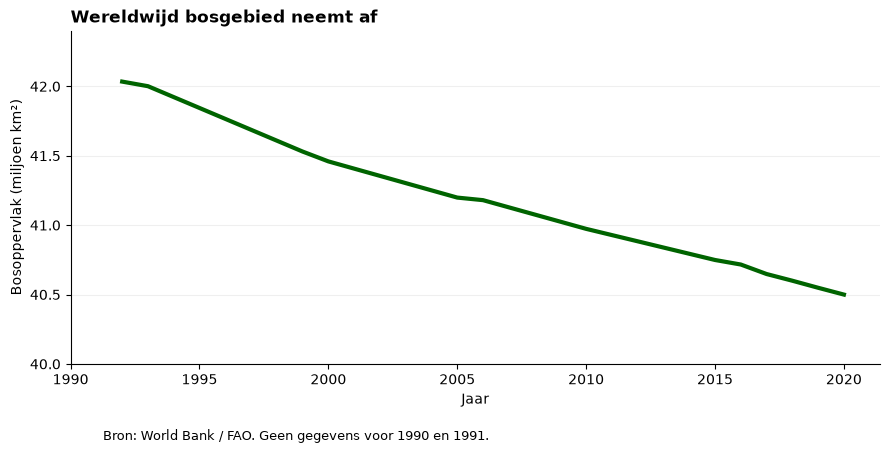

In [5]:
# AI-bron: prompt 2 (werkversie A, C en E).
wereld = bos[bos["area_name"] == "World"]
wereld = wereld[wereld["year"].between(1990, 2020)]

plt.figure(figsize=(9, 4.5))
plt.plot(wereld["year"], wereld["forest_area"] / 1_000_000, color="darkgreen", linewidth=3)
plt.title("Wereldwijd bosgebied neemt af", loc="left", fontweight="bold")
plt.xlabel("Jaar")
plt.ylabel("Bosoppervlak (miljoen km²)")
plt.xticks(range(1990, 2021, 5))
plt.ylim(40, 42.4)
plt.grid(axis="y", alpha=0.2)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(0.12, 0.01, "Bron: World Bank / FAO. Geen gegevens voor 1990 en 1991.", fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Onderbouwing A

Grafiekkeuze: Ik heb gekozen voor een lijngrafiek omdat het gaat om veranderingen over tijd. Met een lijngrafiek is het overzichtelijker om te zien wat er na zoveel jaar gebeurt. Een staafdiagram is hiervoor minder handig.

Context: De VN-leiders kunnen zien dat er met de tijd een steeds groter probleem ontstaat. Tussen 1992 en 2020 is er ongeveer 1,53 miljoen km² aan bos verdwenen. Ze kunnen maatregelen nemen om hier een stokje voor te steken.

Clutter: Ik heb de lijnen boven en rechts weggehaald, geen legenda toegevoegd en alleen lichte horizontale hulplijnen gebruikt. Ook worden de jaartallen om de vijf jaar weergegeven, zodat de grafiek overzichtelijker wordt.

Visuele focus: Ik heb gekozen voor groen omdat het over het milieu gaat. De lijn is dik gemaakt omdat deze duidelijk zichtbaar moet zijn en het belangrijkste aandachtspunt is. De achtergrond is rustig gehouden, omdat het anders onnodig druk wordt en voor afleiding zorgt.

## B – Bosgebied per inkomensgroep



In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

forest = pd.read_csv("forest_area_cleaned.csv")

income_groups = [
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_b = forest[forest["area_name"].isin(income_groups)]
forest_b = forest_b[forest_b["year"].between(1990, 2020)]

display(forest_b)

,area_name,area_code,year,forest_area
233,High income,HIC,1990,1.011042e+07
245,Low income,LIC,1990,3.523832e+06
246,Lower middle income,LMC,1990,6.237384e+06
250,Middle income,MIC,1990,NaN
264,Upper middle income,UMC,1990,NaN
...,...,...,...,...
8213,High income,HIC,2020,1.051011e+07
8225,Low income,LIC,2020,2.991863e+06
8226,Lower middle income,LMC,2020,5.845811e+06
8230,Middle income,MIC,2020,2.653541e+07


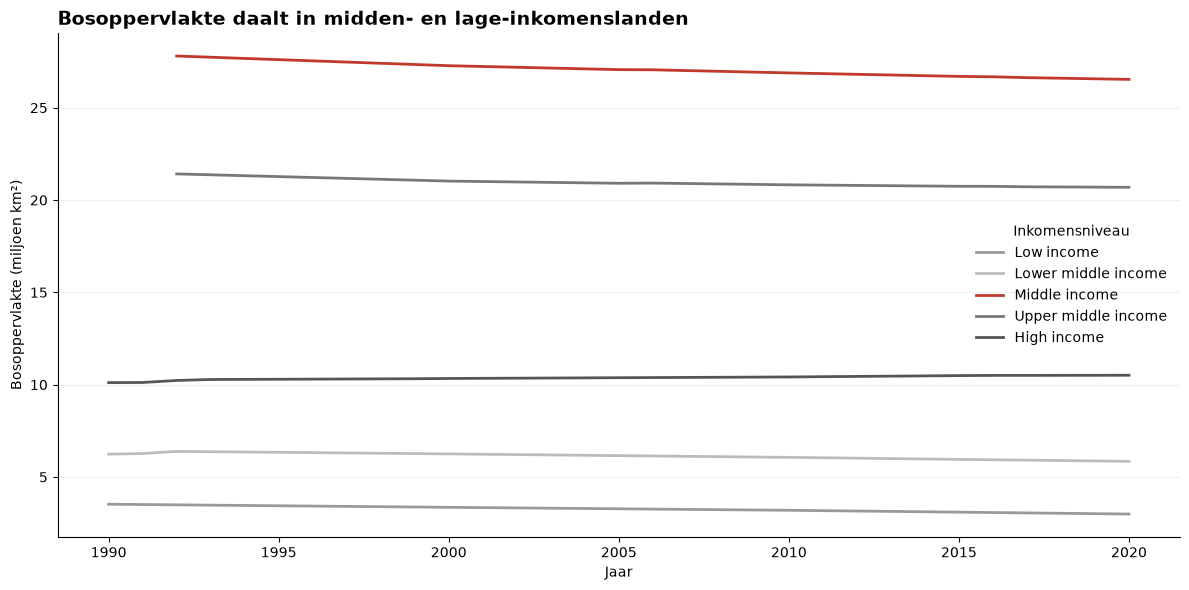

In [9]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=forest_b,
    x="year",
    y=forest_b["forest_area"] / 1000000,
    hue="area_name",
    hue_order=income_groups,
    palette=["#999999", "#BBBBBB", "#C0392B", "#777777", "#555555"],
    linewidth=2
)

plt.title(
    "Bosoppervlakte daalt in midden- en lage-inkomenslanden",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Jaar")
plt.ylabel("Bosoppervlakte (miljoen km²)")
plt.xticks(range(1990, 2021, 5))
plt.legend(title="Inkomensniveau", frameon=False)

plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek B

**Grafiekkeuze:** Ik heb gekozen voor een lijngrafiek omdat
je hiermee veranderingen over tijd goed kunt zien en de
verschillende inkomensgroepen kunt vergelijken.

**Context:** De bosoppervlakte in middeninkomenslanden is
tussen 1992 en 2020 met ongeveer 1,27 miljoen km² afgenomen.
VN-leiders kunnen deze informatie gebruiken om te bepalen
waar extra maatregelen tegen ontbossing nodig zijn.

**Clutter:** Ik heb onnodige randen en het kader rondom de
legenda verwijderd. De rasterlijnen zijn minder opvallend
en de bosoppervlakte wordt weergegeven in miljoenen km².
Hierdoor is de grafiek makkelijker te lezen.

**Preattentive attributes:** Ik heb Middle income rood
gemaakt en de overige lijnen grijs. Door het kleurcontrast
wordt de aandacht direct naar de belangrijkste trend geleid.

Voor Middle income en Upper middle income
ontbreken gegevens uit 1990 en 1991. Middle income omvat
ook Lower middle income en Upper middle income.

## C – Bosontwikkeling in drie landen en de wereld (2018–2020)

Vraag: hebben alle landen dezelfde ontwikkeling als de wereld?

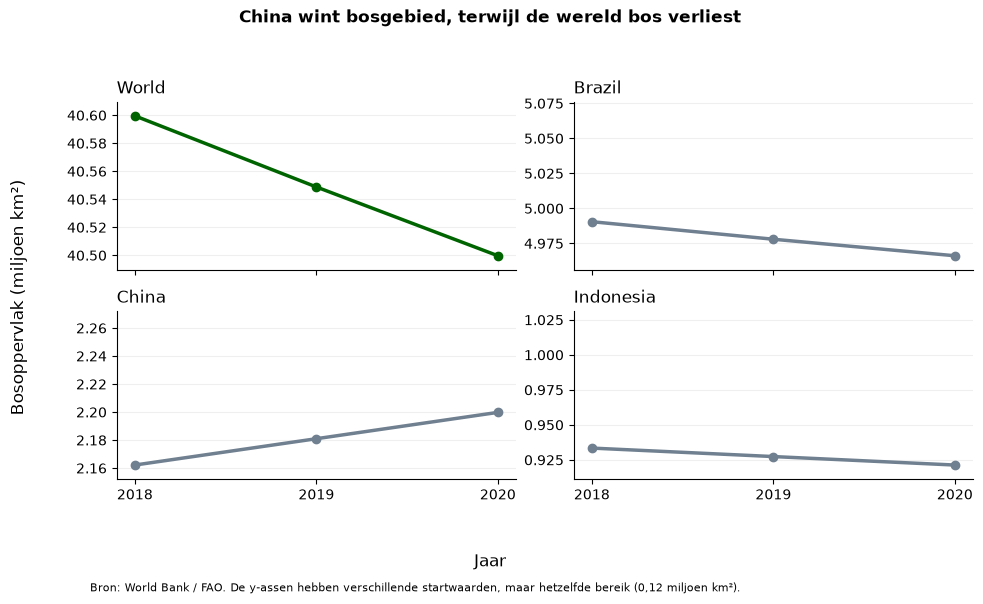

In [6]:
# AI-bron: prompt 2 (werkversie A, C en E).
landen = ["World", "Brazil", "China", "Indonesia"]
vergelijking = bos[bos["area_name"].isin(landen) & bos["year"].between(2018, 2020)]

fig, assen = plt.subplots(2, 2, figsize=(10, 6), sharex=True)

for land, ax in zip(landen, assen.flat):
    gegevens = vergelijking[vergelijking["area_name"] == land]
    oppervlakte = gegevens["forest_area"] / 1_000_000
    kleur = "darkgreen" if land == "World" else "slategray"
    ax.plot(gegevens["year"], oppervlakte, color=kleur, linewidth=2.5, marker="o")
    ax.set_title(land, loc="left")
    ax.set_xticks([2018, 2019, 2020])
    ax.set_ylim(oppervlakte.min() - 0.01, oppervlakte.min() + 0.11)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("China wint bosgebied, terwijl de wereld bos verliest", fontweight="bold")
fig.supylabel("Bosoppervlak (miljoen km²)")
fig.supxlabel("Jaar", y=0.045)
fig.text(0.1, 0.01, "Bron: World Bank / FAO. De y-assen hebben verschillende startwaarden, maar hetzelfde bereik (0,12 miljoen km²).", fontsize=8)
plt.tight_layout(rect=[0.03, 0.08, 1, 0.94])
plt.show()

## Onderbouwing C

**Grafiekkeuze:** Ik heb gekozen voor vier verschillende lijngrafieken omdat de bosoppervlaktes sterk verschillen. Als we alles in één lijngrafiek zouden zetten, zouden de veranderingen per land minder goed zichtbaar zijn. De aparte grafieken hebben hetzelfde verticale bereik, waardoor we de veranderingen goed met elkaar kunnen vergelijken.

**Context:**
- Wereld: bosgebied neemt af.
- Brazilië: bosgebied neemt af.
- Indonesië: bosgebied neemt af.
- China: bosgebied neemt toe.

VN-leiders kunnen onderzoeken waarom China het beter doet dan de andere landen en aan de hand daarvan kijken welke maatregelen andere landen kunnen nemen.

**Clutter:**
- Geen legenda, omdat de landnamen boven de grafieken staan.
- Bovenste en rechterranden verwijderd.
- Lichte horizontale hulplijnen.
- Alle grafieken hebben dezelfde opmaak.

Hierdoor zijn de grafieken rustiger en makkelijker te vergelijken.

**Visuele focus:**
- Groen: benadrukt de wereld als vergelijkingspunt.
- Grijs: geeft de landen minder nadruk.
- Dikke lijnen: maken de trends duidelijk zichtbaar.
- Ronde punten: benadrukken de metingen per jaar.
- Titel: vestigt de aandacht op China, omdat daar het bosgebied juist toeneemt.

## D – Bosgebied in 2020

In [10]:
groups = [
    "World",
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_d = forest[forest["area_name"].isin(groups)]
forest_d = forest_d[forest_d["year"] == 2020]
forest_d = forest_d.sort_values("forest_area")

display(forest_d)

,area_name,area_code,year,forest_area
8225,Low income,LIC,2020,2991863.4
8226,Lower middle income,LMC,2020,5845811.0
8213,High income,HIC,2020,10510106.5
8244,Upper middle income,UMC,2020,20689597.8
8230,Middle income,MIC,2020,26535408.8
8245,World,WLD,2020,40499687.7


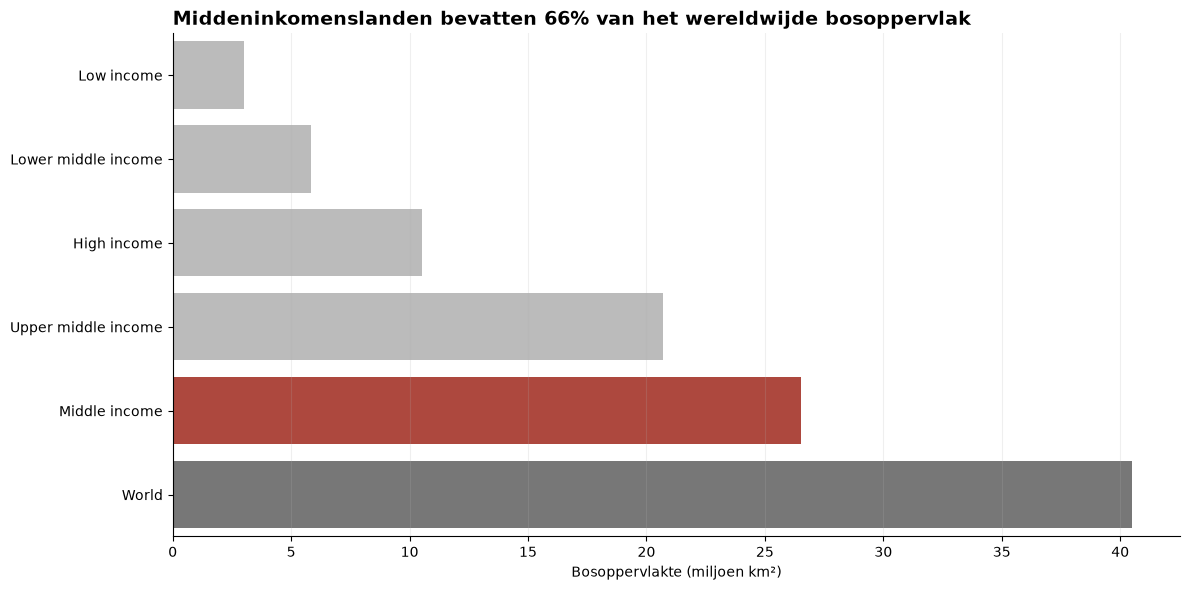

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=forest_d,
    x=forest_d["forest_area"] / 1000000,
    y="area_name",
    hue="area_name",
    palette=["#BBBBBB", "#BBBBBB", "#BBBBBB",
             "#BBBBBB", "#C0392B", "#777777"],
    legend=False
)

plt.title(
    "Middeninkomenslanden bevatten 66% van het wereldwijde bosoppervlak",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Bosoppervlakte (miljoen km²)")
plt.ylabel("")

plt.grid(axis="x", alpha=0.2)
sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek D

**Grafiekkeuze:** Ik heb gekozen voor een horizontaal
staafdiagram omdat je hiermee de bosoppervlakte van
verschillende inkomensgroepen in hetzelfde jaar goed
kunt vergelijken.

**Context:** In 2020 bevond ongeveer 66% van het
wereldwijde bosoppervlak zich in middeninkomenslanden.
Voor VN-leiders zijn deze landen daarom belangrijk
bij het opstellen van maatregelen voor bosbescherming.

**Clutter:** Ik heb onnodige randen, de legenda en het
label van de Y-as verwijderd. De rasterlijnen zijn
minder opvallend gemaakt om afleiding te verminderen.

**Preattentive attributes:** Ik heb de staaf van Middle
income rood gemaakt om hier de aandacht op te richten.
Daarnaast zijn de staven gesorteerd op grootte,
waardoor de verschillen direct zichtbaar zijn.

World is het wereldtotaal. Middle income
omvat ook Lower middle income en Upper middle income.
De categorieën mogen daarom niet worden opgeteld.

## E – Gemiddelde temperatuur per jaar (1995–2019)

Vraag: hoe ontwikkelt de gemiddelde temperatuur zich volgens de beschikbare stadsmetingen?

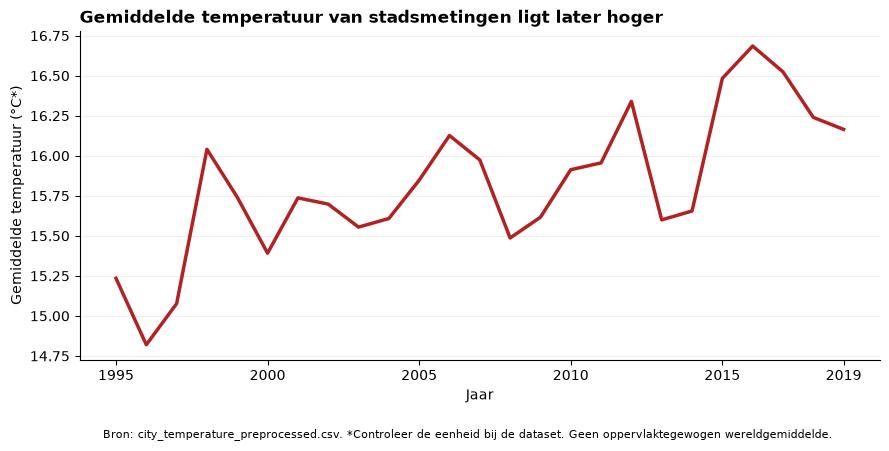

In [7]:
# AI-bron: prompt 2 (werkversie A, C en E).
temperatuur_periode = temperatuur[temperatuur["Year"].between(1995, 2019)]
jaargemiddelde = temperatuur_periode.groupby("Year")["AvgTemperature"].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(jaargemiddelde.index, jaargemiddelde.values, color="firebrick", linewidth=2.5)
plt.title("Gemiddelde temperatuur van stadsmetingen ligt later hoger", loc="left", fontweight="bold")
plt.xlabel("Jaar")
plt.ylabel("Gemiddelde temperatuur (°C*)")
plt.xticks([1995, 2000, 2005, 2010, 2015, 2019])
plt.grid(axis="y", alpha=0.2)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(0.12, 0.015, "Bron: city_temperature_preprocessed.csv. *Controleer de eenheid bij de dataset. Geen oppervlaktegewogen wereldgemiddelde.", fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Onderbouwing E

Grafiekkeuze: Deze lijngrafiek laat duidelijk zien hoe de gemiddelde temperatuur over tijd verandert.

Context: Je ziet dat de gemiddelde temperatuur van de stadsmetingen later hoger ligt. Hierdoor kunnen de VN-leiders inzien dat er maatregelen genomen moeten worden om verdere opwarming tegen te gaan.

Clutter:
- Geen onnodige legenda.
- Bovenste en rechterrand verwijderd.
- Lichte horizontale hulplijnen.
- Beperkt aantal jaartallen.

Dit maakt de grafiek veel minder druk en daardoor overzichtelijker.

Visuele focus:
- Rode kleur, omdat rood met warmte wordt geassocieerd.
- Dikke lijn om de aandacht te trekken.
- Rustige achtergrond om afleiding te voorkomen.

## F – Maandelijkse temperatuur Nederland


In [12]:
temperature = pd.read_csv("city_temperature_preprocessed.csv")

temperature_f = temperature[temperature["Country"] == "The Netherlands"]

display(temperature_f)

,Region,Country,City,Month,Day,Year,AvgTemperature
767088,Europe,The Netherlands,Amsterdam,1,1,1995,3.1
767089,Europe,The Netherlands,Amsterdam,1,2,1995,3.7
767090,Europe,The Netherlands,Amsterdam,1,3,1995,0.7
767091,Europe,The Netherlands,Amsterdam,1,4,1995,-1.6
767092,Europe,The Netherlands,Amsterdam,1,5,1995,-3.4
...,...,...,...,...,...,...,...
776185,Europe,The Netherlands,Amsterdam,12,27,2019,4.0
776186,Europe,The Netherlands,Amsterdam,12,28,2019,0.7
776187,Europe,The Netherlands,Amsterdam,12,29,2019,1.5
776188,Europe,The Netherlands,Amsterdam,12,30,2019,4.6


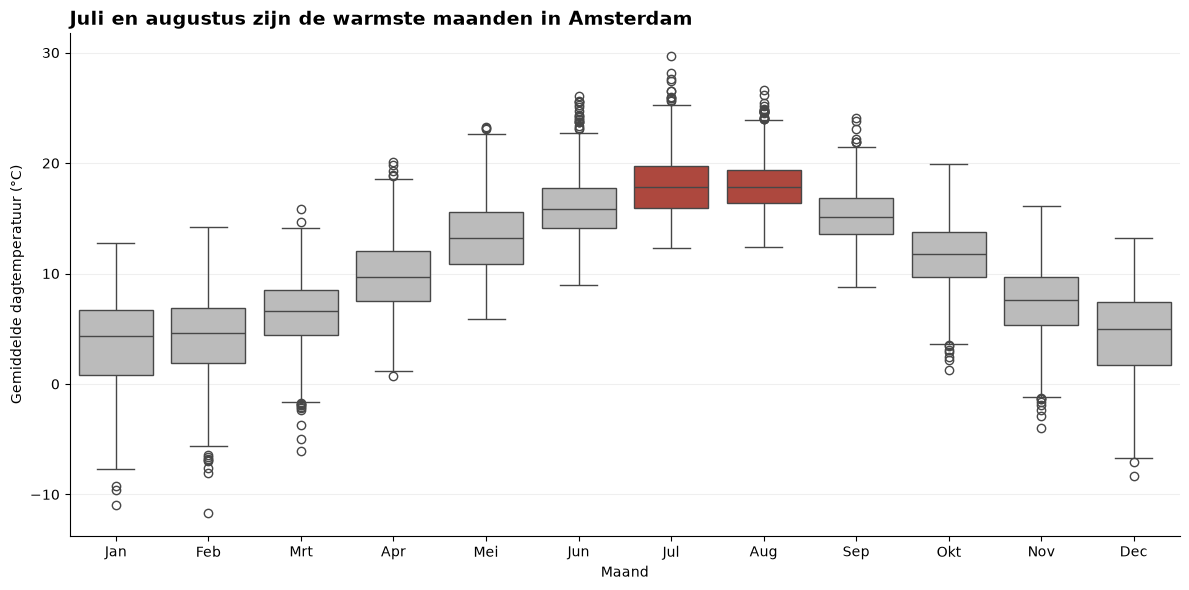

In [13]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=temperature_f,
    x="Month",
    y="AvgTemperature",
    hue="Month",
    palette=[
        "#BBBBBB", "#BBBBBB", "#BBBBBB",
        "#BBBBBB", "#BBBBBB", "#BBBBBB",
        "#C0392B", "#C0392B", "#BBBBBB",
        "#BBBBBB", "#BBBBBB", "#BBBBBB"
    ],
    legend=False
)

plt.title(
    "Juli en augustus zijn de warmste maanden in Amsterdam",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Maand")
plt.ylabel("Gemiddelde dagtemperatuur (°C)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mrt", "Apr", "Mei", "Jun",
     "Jul", "Aug", "Sep", "Okt", "Nov", "Dec"]
)

plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek F

**Grafiekkeuze:** Ik heb gekozen voor boxplots omdat
je hiermee de mediaan, spreiding en uitschieters van
de temperaturen per maand goed kunt vergelijken.

**Context:** Uit de temperatuurgegevens van 1995 tot
en met 2019 blijkt dat juli en augustus de warmste
maanden zijn. Beide maanden hebben een mediane
dagtemperatuur van 17,8 °C.

**Clutter:** Ik heb onnodige randen en de legenda
verwijderd. Ook heb ik korte maandnamen gebruikt en
de rasterlijnen minder opvallend gemaakt.

**Preattentive attributes:** Ik heb juli en augustus
rood gemaakt en de overige maanden grijs. Hierdoor
wordt de aandacht direct naar de warmste maanden
geleid.

De Nederlandse temperatuurgegevens
in deze dataset zijn afkomstig uit Amsterdam.

## Impact-evaluatie AI – nog zelf aanvullen

AI is ingezet voor uitleg over de opdracht, GitHub, het inladen van data en het voorbereiden van voorbeeldcode en ontwerpkeuzes voor A, C en E. De voorbeeldcode is uitgevoerd met de aangeleverde bestanden. De temperatuur-eenheid is niet gedocumenteerd in het CSV-bestand en moet nog bij de cursusbron worden geverifieerd. Het gemiddelde is niet geografisch gewogen.

**Vul zelf aan:** welke onderdelen heb je daadwerkelijk gebruikt, zelfstandig geschreven of aangepast? Welke positieve en negatieve effecten heb je ervaren? Hoe heb je de resultaten gecontroleerd en de beperkingen aangepakt? Controleer dat maximaal 50% van alle code in het gezamenlijke notebook letterlijk of vrijwel letterlijk uit bronnen komt.

## Referenties – nog aanvullen

- World Bank. (z.d.). *Forest area (sq. km)*. https://data.worldbank.org/indicator/AG.LND.FRST.K2?view=chart (voorbewerkte dataset `forest_area_cleaned.csv` via Brightspace).
- [Auteur/organisatie en jaar controleren]. *city_temperature_preprocessed.csv* [Dataset]. Brightspace, Visualisatie & Storytelling.
- ChatGPT (GPT-6.2, 2026). Prompt 1: Dataset inladen en filteren. [Voeg de echte gedeelde gesprekslink toe].
- ChatGPT (GPT-6.2, 2026). Prompt 2: Werkversie opdrachten A, C en E (met rubric). [Voeg de echte gedeelde gesprekslink toe].

Pas de promptnummering en titels aan op jullie echte prompts, voeg ook de overige gebruikte bronnen en prompts toe en volg de deelinstructies van de opleiding.